In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import sys, json, math
import numpy as np, torch
import torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
sys.path.insert(0, '/Users/faenegoro/Documents/Neuroimaging/BrainOmni')
from brainomni.model import BrainOmni
device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
print('Device:', device)

W0728 22:07:37.273000 15249 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Device: mps


In [2]:
# Last-1 block, 5-fold CV, NN head. Runs each fold until the TRAIN (blue) loss
# plateaus, then stops automatically (capped at MAX_EPOCHS). Best epoch still chosen
# on inner-val, so the reported number is unaffected by the extra epochs.
CKPT_PATH = '/Users/faenegoro/Documents/Neuroimaging/BrainOmni/ckpt_collection/tiny'
SAVE_DIR  = '../data/preprocessed'
OUT_DIR   = '../results/figures'
os.makedirs(OUT_DIR, exist_ok=True)
with open(os.path.join(CKPT_PATH, 'model_cfg.json')) as f:
    model_config = json.load(f)
base_checkpoint = torch.load(os.path.join(CKPT_PATH, 'BrainOmni.pt'), map_location='cpu', weights_only=True)
proj_out1 = np.load(os.path.join(SAVE_DIR, 'proj_out1.npy'))
proj_out2 = np.load(os.path.join(SAVE_DIR, 'proj_out2.npy'))
labels    = np.load(os.path.join(SAVE_DIR, 'labels.npy'))
N = len(labels)
FROZEN_CV, HANDCRAFT_CV = 0.831, 0.872
BACKBONE_LR, HEAD_LR = 1e-5, 1e-4
N_FROZEN   = 10     # last 1 block trainable
MAX_EPOCHS = 500    # hard cap (scheduler length); auto-stops earlier when train plateaus
TRAIN_TOL, TRAIN_PATIENCE = 0.002, 40   # "train stabilized" = no >0.002 drop for 40 epochs
print('N =', N, '| last 1 block | cap', MAX_EPOCHS)

N = 148 | last 1 block | cap 500


In [3]:
class CachedMEGDataset(Dataset):
    def __init__(self, indices, c1, c2, labels): self.i, self.c1, self.c2, self.y = indices, c1, c2, labels
    def __len__(self): return len(self.i)
    def __getitem__(self, k):
        j = self.i[k]; return self.c1[j], self.c2[j], torch.tensor(self.y[j], dtype=torch.long)

class FinetuneClassifier(nn.Module):
    def __init__(self, blocks, hidden_dim=256):
        super().__init__(); self.blocks = blocks
        self.head = nn.Sequential(nn.Linear(hidden_dim*16, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x1, x2):
        x1, x2 = x1.to(device), x2.to(device)
        for b in self.blocks: x1 = b(x1); x2 = b(x2)
        x1 = F.normalize(x1, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        x2 = F.normalize(x2, p=2.0, dim=-1, eps=1e-6).mean(dim=2)
        return self.head(((x1 + x2)/2).flatten(1))

def make_warmup_cosine(opt, total, warm=0.1, wmin=0.1, cmin=0.1):
    ws = max(1, int(total*warm))
    def f(s):
        if s < ws: return wmin + (1-wmin)*s/ws
        p = (s-ws)/max(1, total-ws); return cmin + (1-cmin)*0.5*(1+math.cos(math.pi*p))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def fresh_frozen_model():
    m = BrainOmni(**model_config); m.load_state_dict(base_checkpoint, strict=False)
    for p in m.parameters(): p.requires_grad = False
    return m.to(device).eval()

def cache_frozen(model, n_frozen):
    c1, c2 = [], []
    with torch.no_grad():
        for i in range(N):
            x1 = torch.tensor(proj_out1[i]).unsqueeze(0).to(device)
            x2 = torch.tensor(proj_out2[i]).unsqueeze(0).to(device)
            for b in list(model.blocks)[:n_frozen]: x1 = b(x1); x2 = b(x2)
            c1.append(x1.squeeze(0).cpu()); c2.append(x2.squeeze(0).cpu())
    return c1, c2
print('Helpers 1 ready.')

Helpers 1 ready.


In [4]:
def train_until_stable(n_frozen, tr, va, c1, c2, model, monitor_idx=None):
    tl_loader = DataLoader(CachedMEGDataset(tr, c1, c2, labels), batch_size=8, shuffle=True)
    vl_loader = DataLoader(CachedMEGDataset(va, c1, c2, labels), batch_size=8)
    mn_loader = DataLoader(CachedMEGDataset(monitor_idx, c1, c2, labels), batch_size=8) if monitor_idx is not None else None
    unfrozen = nn.ModuleList(list(model.blocks)[n_frozen:-1])
    for p in unfrozen.parameters(): p.requires_grad = True
    ft = FinetuneClassifier(unfrozen, 256).to(device)
    opt = torch.optim.AdamW([{'params': ft.blocks.parameters(), 'lr': BACKBONE_LR, 'weight_decay': 0.05},
                             {'params': ft.head.parameters(),   'lr': HEAD_LR,     'weight_decay': 0.05}],
                            betas=(0.9, 0.99), eps=1e-6)
    sched = make_warmup_cosine(opt, MAX_EPOCHS * len(tl_loader))
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    def ev(loader):
        ft.eval(); p, t, ls = [], [], 0.0
        with torch.no_grad():
            for x1, x2, y in loader:
                o = ft(x1, x2); ls += crit(o, y.to(device)).item()
                p.extend(o.argmax(1).cpu().numpy()); t.extend(y.numpy())
        return accuracy_score(t, p), ls/len(loader)
    best_vl, best_ep, best_w = float('inf'), 0, None
    best_trl, tr_pc, stop_ep = float('inf'), 0, MAX_EPOCHS
    ta, vacc, tl, vl, mona, monl = [], [], [], [], [], []
    for epoch in range(MAX_EPOCHS):
        ft.train(); preds, trues, el = [], [], 0.0
        for x1, x2, y in tl_loader:
            opt.zero_grad(); o = ft(x1, x2); loss = crit(o, y.to(device)); loss.backward()
            torch.nn.utils.clip_grad_norm_(ft.parameters(), 1.0); opt.step(); sched.step()
            el += loss.item(); preds.extend(o.argmax(1).cpu().numpy()); trues.extend(y.numpy())
        tra, trl = accuracy_score(trues, preds), el/len(tl_loader)
        va_, vll = ev(vl_loader)
        if mn_loader is not None:
            ma_, mll = ev(mn_loader); mona.append(ma_); monl.append(mll)
        ta.append(tra); vacc.append(va_); tl.append(trl); vl.append(vll)
        if vll < best_vl - 1e-4:
            best_vl, best_ep = vll, epoch+1; best_w = {k: v.clone() for k, v in ft.state_dict().items()}
        # train-plateau detector: stop when train loss stops dropping
        if trl < best_trl - TRAIN_TOL: best_trl, tr_pc = trl, 0
        else: tr_pc += 1
        if tr_pc >= TRAIN_PATIENCE:
            stop_ep = epoch+1; break
    if best_w is not None: ft.load_state_dict(best_w)
    hist = {'best_ep': best_ep, 'stop_ep': stop_ep, 'train_accs': ta, 'val_accs': vacc,
            'train_losses': tl, 'val_losses': vl}
    if mn_loader is not None: hist['mon_accs'] = mona; hist['mon_losses'] = monl
    return ft, hist

def nn_predict(ft, idx, c1, c2):
    ft.eval(); yt, yp, ypr = [], [], []
    with torch.no_grad():
        for i in idx:
            o = ft(c1[i].unsqueeze(0), c2[i].unsqueeze(0))
            ypr.append(torch.softmax(o, 1)[0, 1].item()); yp.append(o.argmax(1).item()); yt.append(labels[i])
    return np.array(yt), np.array(yp), np.array(ypr)
print('Helpers 2 ready.')

Helpers 2 ready.


In [5]:
def run_cv_last1(n_splits=5, seed=123, inner_val=0.15):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.full(N, -1, int); pred = np.zeros(N, int); prob = np.zeros(N); folds, fh = [], []
    for f, (tr, te) in enumerate(skf.split(np.arange(N), labels)):
        itr, iva = train_test_split(tr, test_size=inner_val, stratify=labels[tr], random_state=seed)
        model = fresh_frozen_model(); c1, c2 = cache_frozen(model, N_FROZEN)
        ft, hist = train_until_stable(N_FROZEN, itr, iva, c1, c2, model, monitor_idx=te)
        fh.append(hist)
        yt, yp, ypr = nn_predict(ft, te, c1, c2)
        pred[te], prob[te], oof[te] = yp, ypr, labels[te]; folds.append(accuracy_score(labels[te], yp))
        print(f'  fold {f+1}: train stabilized ~epoch {hist["stop_ep"]} | best_ep {hist["best_ep"]} | acc {folds[-1]:.3f}')
    return {'mean': float(np.mean(folds)), 'folds': folds, 'y_true': oof, 'pred': pred, 'prob': prob, 'fold_hist': fh}

cv = run_cv_last1()
print(f'\nLast-1 CV acc: {cv["mean"]:.3f}  (frozen+LR baseline {FROZEN_CV})')

/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  fold 1: train stabilized ~epoch 406 | best_ep 87 | acc 0.567


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  fold 2: train stabilized ~epoch 474 | best_ep 119 | acc 0.900


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  fold 3: train stabilized ~epoch 489 | best_ep 116 | acc 0.900


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  fold 4: train stabilized ~epoch 382 | best_ep 360 | acc 0.724


/opt/miniconda3/envs/brainomni/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  fold 5: train stabilized ~epoch 441 | best_ep 112 | acc 0.724

Last-1 CV acc: 0.763  (frozen+LR baseline 0.831)


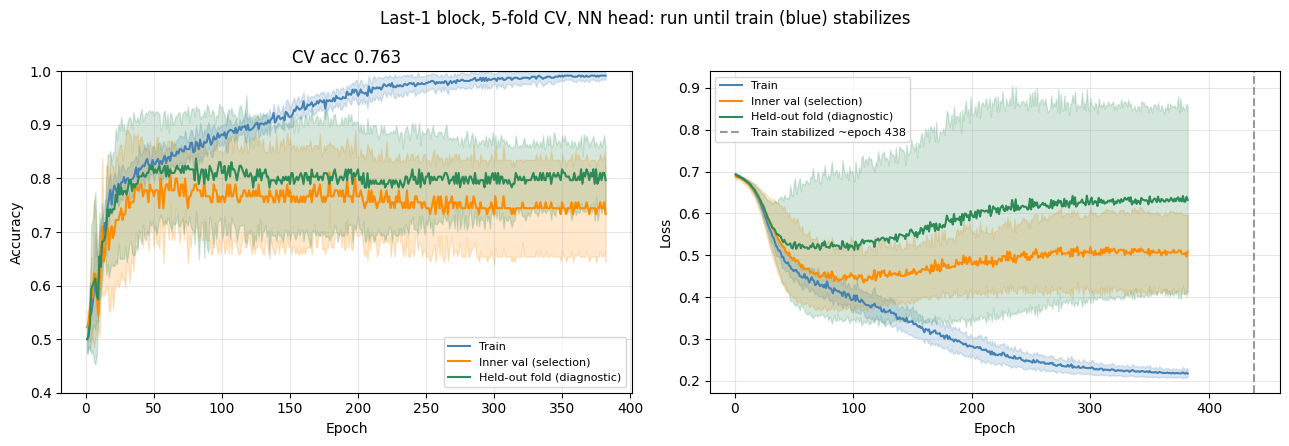

Train loss stabilized around epoch 438 (mean across folds).
Saved last1_cv_converge.png


In [6]:
# Learning curve + mark where the TRAIN (blue) line stabilized (mean stop epoch).
hs = cv['fold_hist']; L = min(len(h['train_losses']) for h in hs); ep = np.arange(1, L+1)
stop_mean = int(np.mean([h['stop_ep'] for h in hs]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
def band(ax, key, color, label):
    M = np.array([h[key][:L] for h in hs]); m, s = M.mean(0), M.std(0)
    ax.plot(ep, m, color=color, label=label); ax.fill_between(ep, m-s, m+s, color=color, alpha=0.2)
band(axes[0], 'train_accs', 'steelblue',  'Train')
band(axes[0], 'val_accs',   'darkorange', 'Inner val (selection)')
band(axes[0], 'mon_accs',   'seagreen',   'Held-out fold (diagnostic)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0.4, 1.0)
axes[0].set_title(f'CV acc {cv["mean"]:.3f}'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
band(axes[1], 'train_losses', 'steelblue',  'Train')
band(axes[1], 'val_losses',   'darkorange', 'Inner val (selection)')
band(axes[1], 'mon_losses',   'seagreen',   'Held-out fold (diagnostic)')
axes[1].axvline(stop_mean, color='gray', ls='--', alpha=0.8, label=f'Train stabilized ~epoch {stop_mean}')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.suptitle('Last-1 block, 5-fold CV, NN head: run until train (blue) stabilizes', fontsize=12)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'last1_cv_converge.png'), dpi=150); plt.show()
print(f'Train loss stabilized around epoch {stop_mean} (mean across folds).')
print('Saved last1_cv_converge.png')

In [7]:
torch.save({'cv': cv, 'n_frozen': N_FROZEN, 'max_epochs': MAX_EPOCHS},
           os.path.join(SAVE_DIR, 'last1_cv_converge.pt'))
print('Saved last1_cv_converge.pt')

Saved last1_cv_converge.pt
